# Analyse de l'inclusion financière

Analyse **univariée, bivariée et multivariée** du jeu d'entraînement de l'enquête sur l'inclusion financière en Afrique. La variable étudiée est `bank_account` (`Yes`/`No`). Les résultats décrivent des associations et ne permettent pas de conclure à une causalité.

## 1. Chargement et contrôle des données

Le fichier `Train.csv` est recherché dans le dossier courant ou dans `financial-inclusion`. L'identifiant `uniqueid` sert uniquement aux contrôles et n'entre jamais dans les analyses explicatives.

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import MonteCarloMethod, chi2_contingency, mannwhitneyu
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

candidats = [Path("Train.csv"), Path("financial-inclusion") / "Train.csv"]
chemin_train = next((p for p in candidats if p.is_file()), None)
if chemin_train is None:
    raise FileNotFoundError("Train.csv introuvable. Ouvrez le notebook depuis le dossier du projet.")

df = pd.read_csv(chemin_train)
cible = "bank_account"
variables_numeriques = ["household_size", "age_of_respondent"]
variables_categorielles = [
    "country", "location_type", "cellphone_access", "gender_of_respondent",
    "relationship_with_head", "marital_status", "education_level", "job_type",
]
variables_categorielles_descriptives = ["year"] + variables_categorielles
variables_explicatives = variables_numeriques + variables_categorielles

print(f"Fichier : {chemin_train.resolve()}")
print(f"Observations : {df.shape[0]:,} | Variables : {df.shape[1]}")
print(f"Valeurs manquantes : {df.isna().sum().sum()}")
print(f"Lignes dupliquées : {df.duplicated().sum()}")
print(f"Identifiants répétés : {df['uniqueid'].duplicated().sum()} (l'identifiant seul n'est pas unique entre pays)")
print("\nAnnée d'enquête par pays :")
display(pd.crosstab(df["country"], df["year"]))
display(df.head())

Fichier : C:\Users\DELL\Downloads\images a10\Data-Science\financial-inclusion\Train.csv
Observations : 23,524 | Variables : 13
Valeurs manquantes : 0
Lignes dupliquées : 0
Identifiants répétés : 14789 (l'identifiant seul n'est pas unique entre pays)

Année d'enquête par pays :


year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


## 2. Analyse univariée

On décrit chaque variable séparément. Les proportions accompagnent les effectifs pour les catégories ; les variables numériques sont résumées par moyenne, médiane, dispersion et quantiles.

,effectif,pourcentage
bank_account,,
No,20212,85.9
Yes,3312,14.1


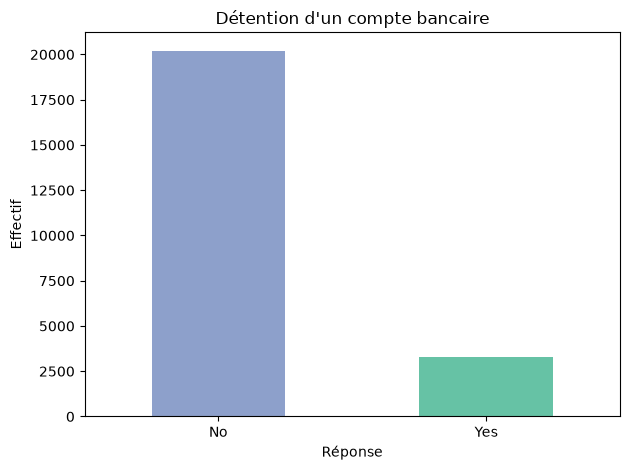

In [23]:
distribution_cible = df[cible].value_counts().rename_axis(cible).to_frame("effectif")
distribution_cible["pourcentage"] = 100 * distribution_cible["effectif"] / len(df)
display(distribution_cible.round(1))

ax = distribution_cible["effectif"].plot(kind="bar", color=["#8da0cb", "#66c2a5"])
ax.set(title="Détention d'un compte bancaire", xlabel="Réponse", ylabel="Effectif")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


year


,effectif,pourcentage
year,,
2016,8735,37.1
2018,8169,34.7
2017,6620,28.1


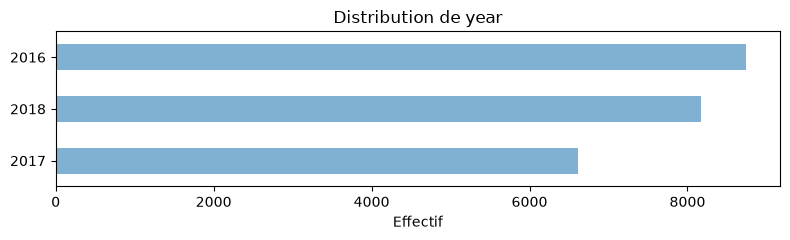


country


,effectif,pourcentage
country,,
Rwanda,8735,37.1
Tanzania,6620,28.1
Kenya,6068,25.8
Uganda,2101,8.9


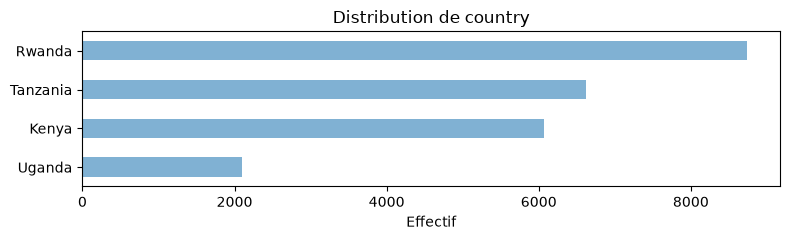


location_type


,effectif,pourcentage
location_type,,
Rural,14343,61.0
Urban,9181,39.0


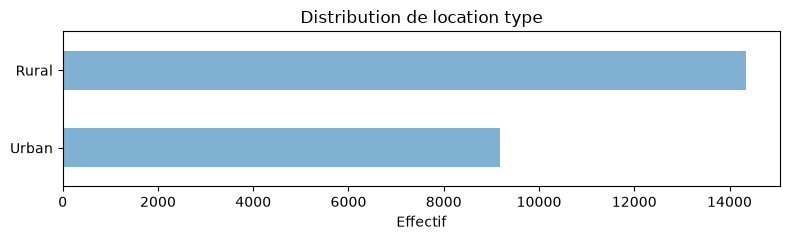


cellphone_access


,effectif,pourcentage
cellphone_access,,
Yes,17454,74.2
No,6070,25.8


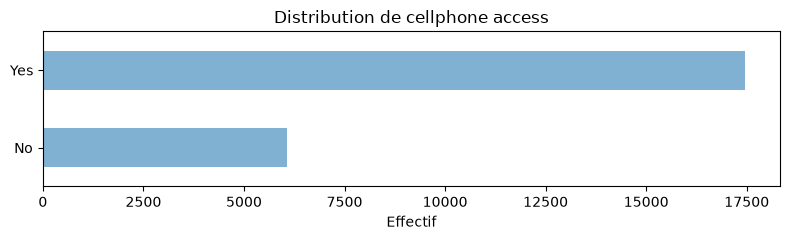


gender_of_respondent


,effectif,pourcentage
gender_of_respondent,,
Female,13877,59.0
Male,9647,41.0


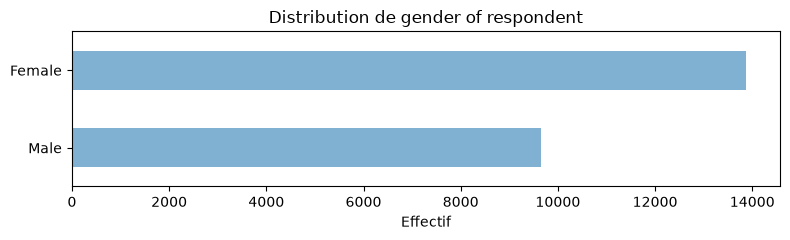


relationship_with_head


,effectif,pourcentage
relationship_with_head,,
Head of Household,12831,54.5
Spouse,6520,27.7
Child,2229,9.5
Parent,1086,4.6
Other relative,668,2.8
Other non-relatives,190,0.8


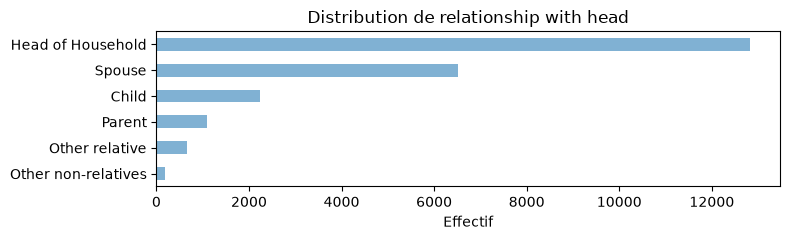


marital_status


,effectif,pourcentage
marital_status,,
Married/Living together,10749,45.7
Single/Never Married,7983,33.9
Widowed,2708,11.5
Divorced/Seperated,2076,8.8
Dont know,8,0.0


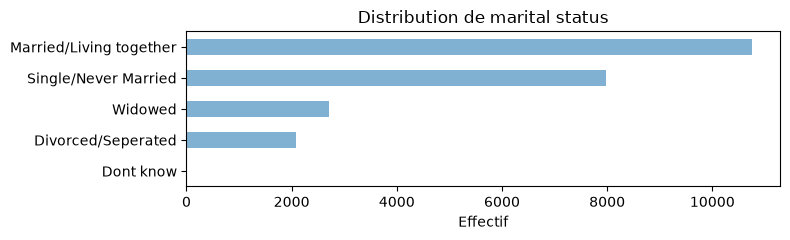


education_level


,effectif,pourcentage
education_level,,
Primary education,12791,54.4
No formal education,4515,19.2
Secondary education,4223,18.0
Tertiary education,1157,4.9
Vocational/Specialised training,803,3.4
Other/Dont know/RTA,35,0.1


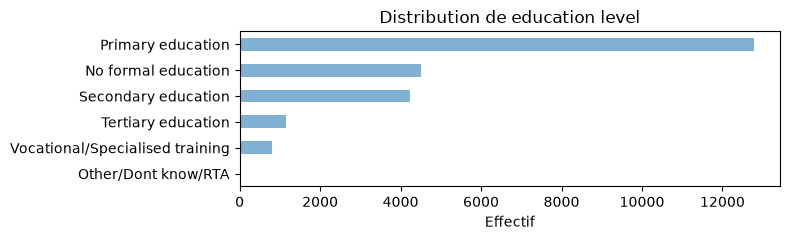


job_type


,effectif,pourcentage
job_type,,
Self employed,6437,27.4
Informally employed,5597,23.8
Farming and Fishing,5441,23.1
Remittance Dependent,2527,10.7
Other Income,1080,4.6
Formally employed Private,1055,4.5
No Income,627,2.7
Formally employed Government,387,1.6
Government Dependent,247,1.0


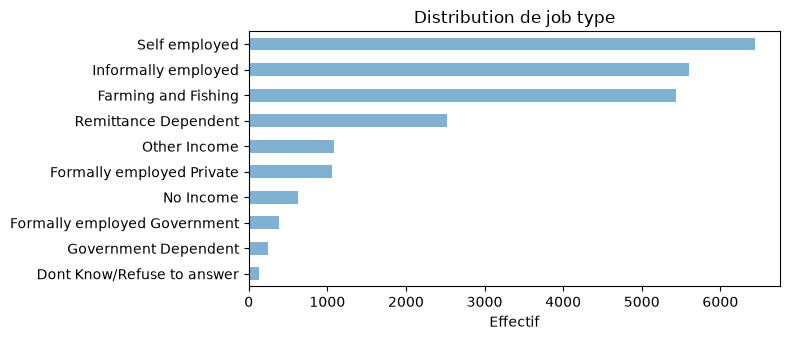

In [24]:
for variable in variables_categorielles_descriptives:
    resume = df[variable].value_counts(dropna=False).rename("effectif").to_frame()
    resume["pourcentage"] = 100 * resume["effectif"] / len(df)
    print(f"\n{variable}")
    display(resume.round(1))

    ax = resume["effectif"].sort_values().plot(kind="barh", figsize=(8, max(2.5, 0.35 * len(resume))), color="#80b1d3")
    ax.set(title=f"Distribution de {variable.replace('_', ' ')}", xlabel="Effectif", ylabel="")
    plt.tight_layout()
    plt.show()

,count,mean,std,min,25%,50%,75%,max,asymetrie
household_size,23524.0,3.80,2.23,1.0,2.0,3.0,5.0,21.0,0.99
age_of_respondent,23524.0,38.81,16.52,16.0,26.0,35.0,49.0,100.0,0.84


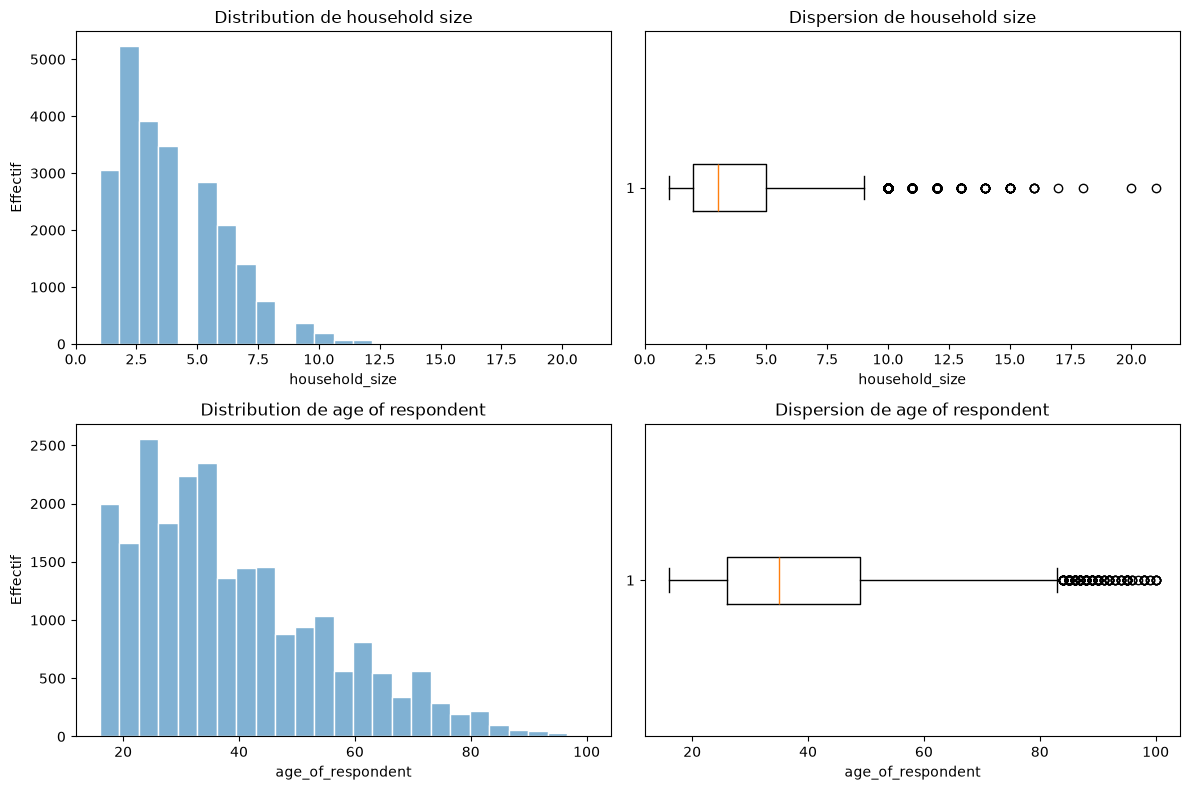

In [25]:
resume_numeriques = df[variables_numeriques].describe().T
resume_numeriques["asymetrie"] = df[variables_numeriques].skew()
display(resume_numeriques.round(2))

fig, axes = plt.subplots(len(variables_numeriques), 2, figsize=(12, 4 * len(variables_numeriques)))
for ligne, variable in enumerate(variables_numeriques):
    axes[ligne, 0].hist(df[variable].dropna(), bins=25, color="#80b1d3", edgecolor="white")
    axes[ligne, 0].set(title=f"Distribution de {variable.replace('_', ' ')}", xlabel=variable, ylabel="Effectif")
    axes[ligne, 1].boxplot(df[variable].dropna(), orientation="horizontal")
    axes[ligne, 1].set(title=f"Dispersion de {variable.replace('_', ' ')}", xlabel=variable)
plt.tight_layout()
plt.show()

## 3. Analyse bivariée

On étudie chaque caractéristique par rapport à la cible. Pour les catégories, le taux `Yes` est accompagné de l'effectif et testé par chi-deux ; le V de Cramér mesure l'intensité de l'association. Pour les nombres, le test de Mann–Whitney compare `Yes` et `No`, avec une taille d'effet de rang bisérial. La correction de Holm ajuste ensemble les p-values, mais ne corrige pas un éventuel plan de sondage complexe. En l'absence de poids, de strates et d'identifiants de grappes, ces tests et leurs p-values sont à lire comme exploratoires, sous l'hypothèse simplificatrice d'observations indépendantes. L'année est décrite, mais n'est pas testée séparément : elle est confondue avec le pays dans cet échantillon.

Taux par couple pays-année (les années ne sont pas communes à tous les pays) :


,,effectif,taux_Yes_pct
country,year,,
Kenya,2018,6068,25.1
Rwanda,2016,8735,11.5
Tanzania,2017,6620,9.2
Uganda,2018,2101,8.6



country selon bank_account


,effectif,taux_Yes_pct
country,,
Kenya,6068,25.1
Rwanda,8735,11.5
Tanzania,6620,9.2
Uganda,2101,8.6


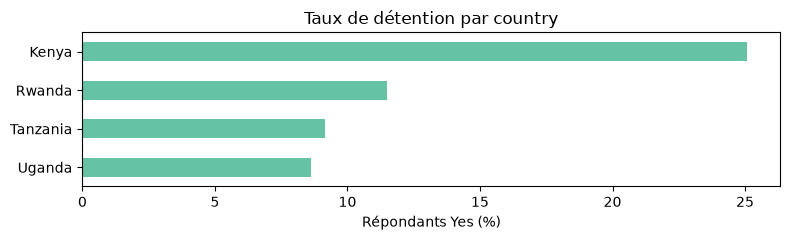


location_type selon bank_account


,effectif,taux_Yes_pct
location_type,,
Urban,9181,17.9
Rural,14343,11.7


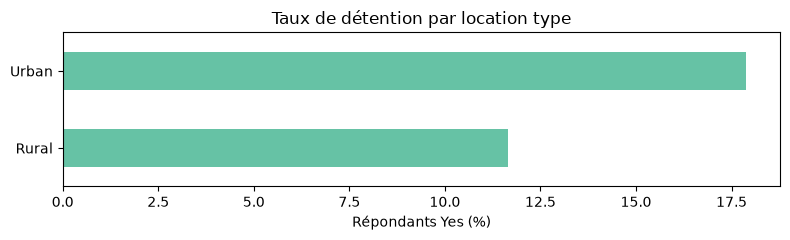


cellphone_access selon bank_account


,effectif,taux_Yes_pct
cellphone_access,,
Yes,17454,18.4
No,6070,1.7


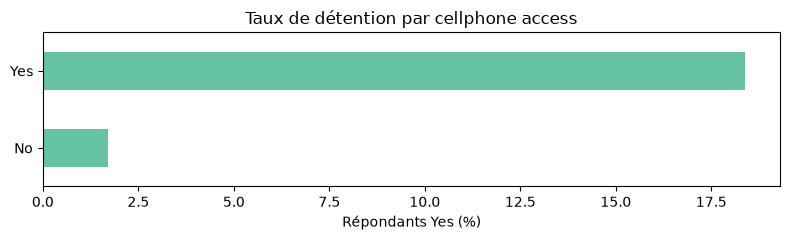


gender_of_respondent selon bank_account


,effectif,taux_Yes_pct
gender_of_respondent,,
Male,9647,19.0
Female,13877,10.7


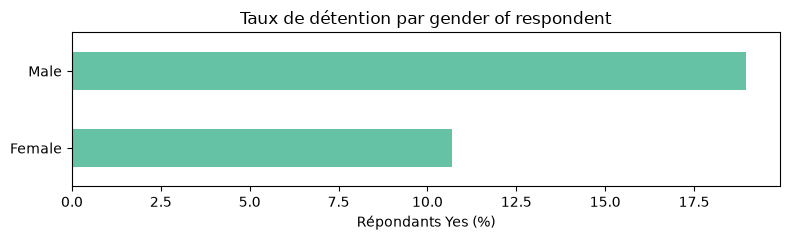


relationship_with_head selon bank_account


,effectif,taux_Yes_pct
relationship_with_head,,
Head of Household,12831,17.7
Spouse,6520,10.7
Other non-relatives,190,10.5
Other relative,668,9.9
Child,2229,8.7
Parent,1086,6.0


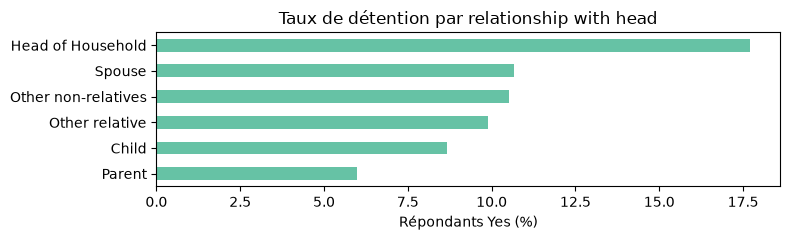


marital_status selon bank_account


,effectif,taux_Yes_pct
marital_status,,
Dont know,8,25.0
Married/Living together,10749,17.4
Single/Never Married,7983,12.1
Divorced/Seperated,2076,11.3
Widowed,2708,9.0


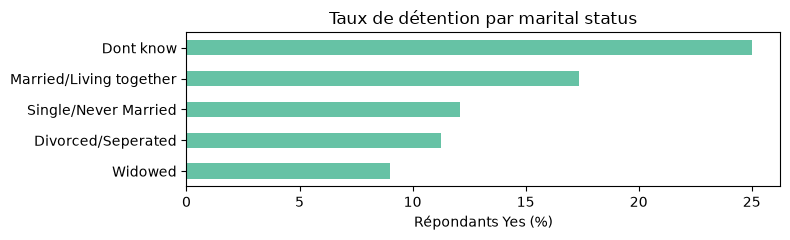


education_level selon bank_account


,effectif,taux_Yes_pct
education_level,,
Vocational/Specialised training,803,57.0
Tertiary education,1157,51.1
Other/Dont know/RTA,35,31.4
Secondary education,4223,23.3
Primary education,12791,8.5
No formal education,4515,3.9


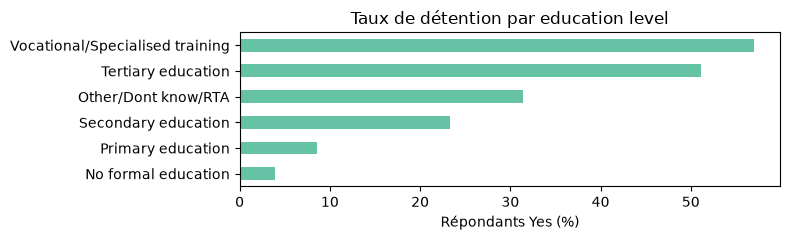


job_type selon bank_account


,effectif,taux_Yes_pct
job_type,,
Formally employed Government,387,77.5
Formally employed Private,1055,54.1
Government Dependent,247,20.2
Other Income,1080,18.1
Self employed,6437,13.2
Farming and Fishing,5441,11.7
Dont Know/Refuse to answer,126,11.1
Remittance Dependent,2527,9.5
Informally employed,5597,8.0


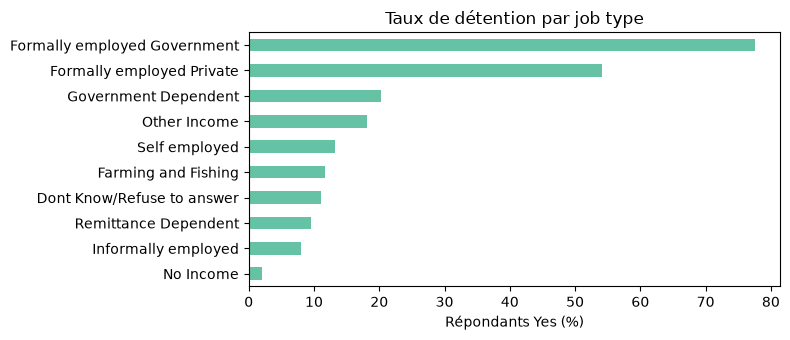

In [26]:
resultats_chi2 = []
rng_tests = np.random.default_rng(42)

resume_pays_annee = (
    df.assign(compte=(df[cible] == "Yes").astype(int))
    .groupby(["country", "year"])
    .agg(effectif=("compte", "size"), taux_Yes_pct=("compte", lambda s: 100 * s.mean()))
)
print("Taux par couple pays-année (les années ne sont pas communes à tous les pays) :")
display(resume_pays_annee.round(1))

for variable in variables_categorielles:
    tableau = pd.crosstab(df[variable], df[cible])
    taux = 100 * tableau.get("Yes", 0) / tableau.sum(axis=1)
    resume = pd.DataFrame({"effectif": tableau.sum(axis=1), "taux_Yes_pct": taux})
    print(f"\n{variable} selon {cible}")
    display(resume.sort_values("taux_Yes_pct", ascending=False).round(1))

    chi2, p, _, attendus = chi2_contingency(tableau)
    methode = "Chi-deux"
    if (attendus < 5).any():
        resultat_test = chi2_contingency(
            tableau,
            correction=False,
            method=MonteCarloMethod(n_resamples=19999, rng=rng_tests),
        )
        chi2, p, _, attendus = resultat_test
        methode = "Chi-deux Monte-Carlo"
    n = tableau.to_numpy().sum()
    v_cramer = np.sqrt(chi2 / (n * min(tableau.shape[0] - 1, tableau.shape[1] - 1)))
    resultats_chi2.append({
        "variable": variable, "test": methode, "statistique": chi2,
        "taille_effet": v_cramer, "mesure_effet": "V de Cramer",
        "p_brute": p, "effectif_attendu_min": attendus.min(),
    })

    ax = resume.sort_values("taux_Yes_pct")["taux_Yes_pct"].plot(
        kind="barh", figsize=(8, max(2.5, 0.35 * len(resume))), color="#66c2a5"
    )
    ax.set(title=f"Taux de détention par {variable.replace('_', ' ')}", xlabel="Répondants Yes (%)", ylabel="")
    plt.tight_layout()
    plt.show()

tests_chi2 = pd.DataFrame(resultats_chi2)


household_size selon bank_account


,count,mean,median,std
bank_account,,,,
No,20212,3.82,3.0,2.23
Yes,3312,3.64,3.0,2.18



age_of_respondent selon bank_account


,count,mean,median,std
bank_account,,,,
No,20212,38.68,35.0,16.85
Yes,3312,39.60,36.0,14.33


Résumé des tests bivariés (p-values corrigées ensemble par Holm) :


,variable,test,statistique,taille_effet,mesure_effet,p_brute,effectif_attendu_min,p_Holm,significatif_5pct
7,job_type,Chi-deux,3.032254e+03,0.3590,V de Cramer,<1e-300,17.7398,<1e-300,True
2,cellphone_access,Chi-deux,1.032761e+03,0.2095,V de Cramer,1.36e-226,854.6098,1.22e-225,True
0,country,Chi-deux,8.379619e+02,0.1887,V de Cramer,2.53e-181,295.8048,2.02e-180,True
3,gender_of_respondent,Chi-deux,3.226238e+02,0.1171,V de Cramer,3.88e-72,1358.2241,2.72e-71,True
4,relationship_with_head,Chi-deux,3.279067e+02,0.1181,V de Cramer,9.96e-69,26.7506,5.98e-68,True
1,location_type,Chi-deux,1.787210e+02,0.0872,V de Cramer,9.22e-41,1292.6149,4.61e-40,True
9,age_of_respondent,Mann-Whitney,3.598490e+07,0.0751,Rang bisérial,3.89e-12,NaN,1.56e-11,True
8,household_size,Mann-Whitney,3.196131e+07,-0.0451,Rang bisérial,2.46e-05,NaN,7.39e-05,True
6,education_level,Chi-deux Monte-Carlo,3.549125e+03,0.3884,V de Cramer,5.00e-05,4.9277,1.00e-04,True
5,marital_status,Chi-deux Monte-Carlo,1.932919e+02,0.0906,V de Cramer,5.00e-05,1.1263,1.00e-04,True


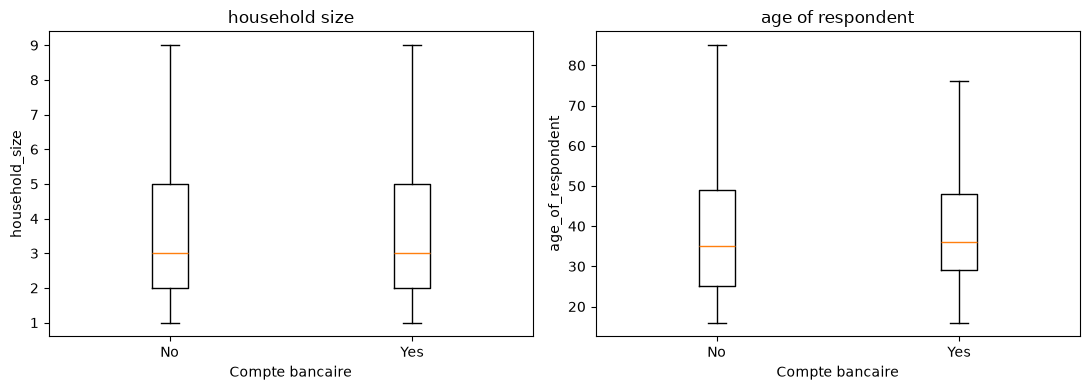

In [27]:
resultats_mw = []
for variable in variables_numeriques:
    groupe_yes = df.loc[df[cible] == "Yes", variable]
    groupe_no = df.loc[df[cible] == "No", variable]
    resultat = mannwhitneyu(groupe_yes, groupe_no, alternative="two-sided")
    rang_biserial = 2 * resultat.statistic / (len(groupe_yes) * len(groupe_no)) - 1
    print(f"\n{variable} selon {cible}")
    display(df.groupby(cible)[variable].agg(["count", "mean", "median", "std"]).round(2))
    resultats_mw.append({
        "variable": variable, "test": "Mann-Whitney",
        "statistique": resultat.statistic,
        "taille_effet": rang_biserial, "mesure_effet": "Rang bisérial",
        "p_brute": resultat.pvalue, "effectif_attendu_min": np.nan,
    })

tests_mw = pd.DataFrame(resultats_mw)
tests_bivaries = pd.concat([tests_chi2, tests_mw], ignore_index=True)
ordre = np.argsort(tests_bivaries["p_brute"].to_numpy())
p_triees = tests_bivaries.iloc[ordre]["p_brute"].to_numpy()
p_holm = np.minimum(1, np.maximum.accumulate((len(p_triees) - np.arange(len(p_triees))) * p_triees))
tests_bivaries["p_Holm"] = np.nan
tests_bivaries.loc[tests_bivaries.index[ordre], "p_Holm"] = p_holm
tests_bivaries["significatif_5pct"] = tests_bivaries["p_Holm"] < 0.05
tests_bivaries_affichage = tests_bivaries.sort_values("p_Holm").copy()
for colonne in ["p_brute", "p_Holm"]:
    tests_bivaries_affichage[colonne] = tests_bivaries_affichage[colonne].map(
        lambda p: "<1e-300" if p == 0 else f"{p:.2e}"
    )
print("Résumé des tests bivariés (p-values corrigées ensemble par Holm) :")
display(tests_bivaries_affichage.round(4))

fig, axes = plt.subplots(1, len(variables_numeriques), figsize=(11, 4))
for ax, variable in zip(axes, variables_numeriques):
    groupes = [df.loc[df[cible] == classe, variable].to_numpy() for classe in ["No", "Yes"]]
    ax.boxplot(groupes, tick_labels=["No", "Yes"], showfliers=False)
    ax.set(title=variable.replace("_", " "), xlabel="Compte bancaire", ylabel=variable)
plt.tight_layout()
plt.show()

## 4. Analyse multivariée

Une régression logistique estime les associations à caractéristiques égales pour les autres variables incluses. La validation stratifiée est reproductible. Les intervalles de confiance à 95 % et les p-values corrigées par Holm sont des estimations de modèle, pas des estimations tenant compte du plan de sondage. Les erreurs-types HC1 corrigent l'hétéroscédasticité, mais ne remplacent ni les poids, ni les strates, ni les grappes d'un sondage. L'année est exclue : le Rwanda est observé en 2016, la Tanzanie en 2017, et le Kenya et l'Ouganda en 2018 ; on ne peut pas isoler son effet de celui du pays. Ces résultats ne prouvent pas de causalité.

In [28]:
X = df[variables_explicatives].copy()
y = (df[cible] == "Yes").astype(int)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preparation = ColumnTransformer(
    transformers=[
        ("numeriques", StandardScaler(), variables_numeriques),
        ("categoriels", OneHotEncoder(handle_unknown="ignore", drop="first"), variables_categorielles),
    ]
)
modele = Pipeline([
    ("preparation", preparation),
    ("regression", LogisticRegression(max_iter=1000)),
])
modele.fit(X_train, y_train)
prediction = modele.predict(X_valid)
probabilite = modele.predict_proba(X_valid)[:, 1]

metriques = pd.Series({
    "Accuracy": accuracy_score(y_valid, prediction),
    "Balanced accuracy": balanced_accuracy_score(y_valid, prediction),
    "Précision (Yes)": precision_score(y_valid, prediction, zero_division=0),
    "Rappel (Yes)": recall_score(y_valid, prediction, zero_division=0),
    "F1 (Yes)": f1_score(y_valid, prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_valid, probabilite),
}, name="score")
display(metriques.round(3).to_frame())

matrice = confusion_matrix(y_valid, prediction, labels=[0, 1])
print("Matrice de confusion au seuil par défaut (0,50)")
display(pd.DataFrame(matrice, index=["Réel No", "Réel Yes"], columns=["Prédit No", "Prédit Yes"]))

comparaison_seuils = []
for seuil in [0.35, 0.50, 0.65]:
    pred_seuil = (probabilite >= seuil).astype(int)
    comparaison_seuils.append({
        "seuil": seuil,
        "precision_Yes": precision_score(y_valid, pred_seuil, zero_division=0),
        "rappel_Yes": recall_score(y_valid, pred_seuil, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_valid, pred_seuil),
    })
print("Seuils illustratifs, non optimisés")
display(pd.DataFrame(comparaison_seuils).set_index("seuil").round(3))

,score
Accuracy,0.888
Balanced accuracy,0.665
Précision (Yes),0.704
Rappel (Yes),0.355
F1 (Yes),0.472
ROC-AUC,0.864


Matrice de confusion au seuil par défaut (0,50)


,Prédit No,Prédit Yes
Réel No,3944,99
Réel Yes,427,235


Seuils illustratifs, non optimisés


,precision_Yes,rappel_Yes,balanced_accuracy
seuil,,,
0.35,0.593,0.485,0.715
0.50,0.704,0.355,0.665
0.65,0.784,0.236,0.613


### Facteurs associés après ajustement

Les OR numériques correspondent à une hausse d'un écart-type. Pour les catégories, la comparaison se fait avec la catégorie de référence indiquée par `OneHotEncoder`. Le tableau utilise un modèle logistique non pénalisé et des erreurs-types robustes HC1 sur toutes les données d'entraînement ; il complète le modèle prédictif validé plus haut.

In [29]:
import statsmodels.api as sm

preparation_inf = ColumnTransformer(
    transformers=[
        ("numeriques", StandardScaler(), variables_numeriques),
        ("categoriels", OneHotEncoder(handle_unknown="ignore", drop="first"), variables_categorielles),
    ]
)
X_encode = preparation_inf.fit_transform(X)
if hasattr(X_encode, "toarray"):
    X_encode = X_encode.toarray()
noms = preparation_inf.get_feature_names_out()
X_inf = pd.DataFrame(X_encode, columns=noms, index=X.index)
X_inf = X_inf.rename(columns=lambda nom: nom.replace("numeriques__", "").replace("categoriels__", ""))
X_inf = sm.add_constant(X_inf, has_constant="add")
modele_inf = sm.Logit(y, X_inf).fit(disp=False, maxiter=100, cov_type="HC1")
ci = modele_inf.conf_int()
resume_inf = pd.DataFrame({
    "OR": np.exp(modele_inf.params),
    "OR_IC95_bas": np.exp(ci[0]),
    "OR_IC95_haut": np.exp(ci[1]),
    "p_brute": modele_inf.pvalues,
}).drop(index="const")

ordre = np.argsort(resume_inf["p_brute"].to_numpy())
p_triees = resume_inf.iloc[ordre]["p_brute"].to_numpy()
p_holm = np.minimum(1, np.maximum.accumulate((len(p_triees) - np.arange(len(p_triees))) * p_triees))
resume_inf["p_Holm"] = np.nan
resume_inf.loc[resume_inf.index[ordre], "p_Holm"] = p_holm
resume_inf["significatif_5pct"] = resume_inf["p_Holm"] < 0.05
resume_inf.index = resume_inf.index.str.replace(r"^(numeriques|categoriels)__", "", regex=True)
resume_inf = resume_inf.sort_values("p_Holm")
resume_affichage = resume_inf.head(20).copy()
for colonne in ["p_brute", "p_Holm"]:
    resume_affichage[colonne] = resume_affichage[colonne].map(lambda p: "<1e-300" if p == 0 else f"{p:.2e}")
display(resume_affichage.round(4))

,OR,OR_IC95_bas,OR_IC95_haut,p_brute,p_Holm,significatif_5pct
education_level_Tertiary education,23.4373,18.7028,29.3703,2.95e-165,9.14e-164,True
education_level_Vocational/Specialised training,16.8791,13.2992,21.4226,1.93e-119,5.79e-118,True
education_level_Secondary education,5.8444,4.8493,7.0438,1.03e-76,2.98e-75,True
cellphone_access_Yes,6.0654,4.9470,7.4367,2.60e-67,7.29e-66,True
country_Tanzania,0.3054,0.2595,0.3595,3.55e-46,9.57e-45,True
country_Uganda,0.2439,0.2003,0.2972,1.27e-44,3.31e-43,True
education_level_Primary education,2.2194,1.8695,2.6348,8.44e-20,2.11e-18,True
age_of_respondent,1.2906,1.2159,1.3698,5.00e-17,1.20e-15,True
relationship_with_head_Head of Household,2.1977,1.7605,2.7434,3.45e-12,7.94e-11,True
gender_of_respondent_Male,1.5103,1.3443,1.6967,3.85e-12,8.48e-11,True


## 5. Conclusion et limites

Dans cet échantillon, 3 312 personnes sur 23 524 déclarent avoir un compte, soit 14,1 %. Le taux est de 18,4 % chez les personnes ayant accès à un téléphone, contre 1,7 % chez celles qui n'y ont pas accès. Il varie également selon le pays, de 8,6 % en Ouganda à 25,1 % au Kenya.

Après ajustement, l'accès au téléphone et les niveaux d'études élevés restent associés à une probabilité estimée plus forte de détenir un compte, par rapport aux catégories de référence. Ces écarts ne prouvent pas que ces caractéristiques causent l'ouverture d'un compte.

Sur l'échantillon de validation, le modèle atteint une ROC-AUC d'environ 0,86. Au seuil de 0,50, il repère toutefois environ 36 % des détenteurs de compte : l'accuracy seule ne suffit donc pas à juger sa capacité à reconnaître la classe minoritaire. Abaisser le seuil augmente le rappel, mais entraîne davantage de faux positifs.

Les p-values et intervalles présentés sont exploratoires et reposent sur une hypothèse d'observations indépendantes ; HC1 ne corrige que l'hétéroscédasticité. Les fichiers fournis ne contiennent ni poids d'enquête, ni strates, ni identifiants de grappes. On ne peut donc pas corriger les incertitudes pour le plan de sondage ni garantir que les résultats représentent la population. Pour lever cette limite, il faudrait récupérer la documentation méthodologique et ces variables auprès de la source de l'enquête ; sans elles, il est préférable de limiter les conclusions aux personnes observées. Enfin, les années d'enquête sont liées aux pays et leurs effets ne peuvent pas être isolés avec ce fichier.